# Image Restoration: Observation Models, Priors and Optimization

**Question:** what can be recovered from a noisy image or from only 10% of its pixels?

Earlier studies chose representations that expose useful structure. Here structure enters as an explicit regularization term. We first study a quadratic's convergence boundary, then implement Tikhonov denoising and constrained inpainting with the same discrete gradient operator.

The baseline objectives and algorithms come from the original work. Parameter comparisons, consistent metrics, deterministic masks and verification against small exact linear systems are additions in this project. No learned model or edge-preserving total-variation solver is claimed.

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Markdown, Image, Audio

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/signal_inverse").is_dir():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
from signal_inverse.datasets import load_inputs
from signal_inverse.experiments import run_restoration

inputs = load_inputs(ROOT / "data")
output = ROOT / "results" / "restoration"

def figure(name):
    display(Image(filename=str(output / (name + ".png")), width=1000))

def table(rows, columns):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in rows:
        values = [f"{row[c]:.3f}" if isinstance(row[c], (float, np.floating)) else str(row[c]) for c in columns]
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

print("Inputs: original course image and recordings bundled in data/.")

Inputs: original course image and recordings bundled in data/.


## 1. Understand the step size on a solvable example

For $f(u,v)=\tfrac12(u^2+8v^2)$, gradient descent obeys

$$u_{k+1}=(1-\tau)u_k,\qquad v_{k+1}=(1-8\tau)v_k.$$

Convergence from any initial point requires $0<\tau<2/8$. At $\tau=0.25$, the second coordinate flips sign without shrinking: reaching the boundary is not convergence. A larger admissible step is not automatically faster on every eigen-direction.

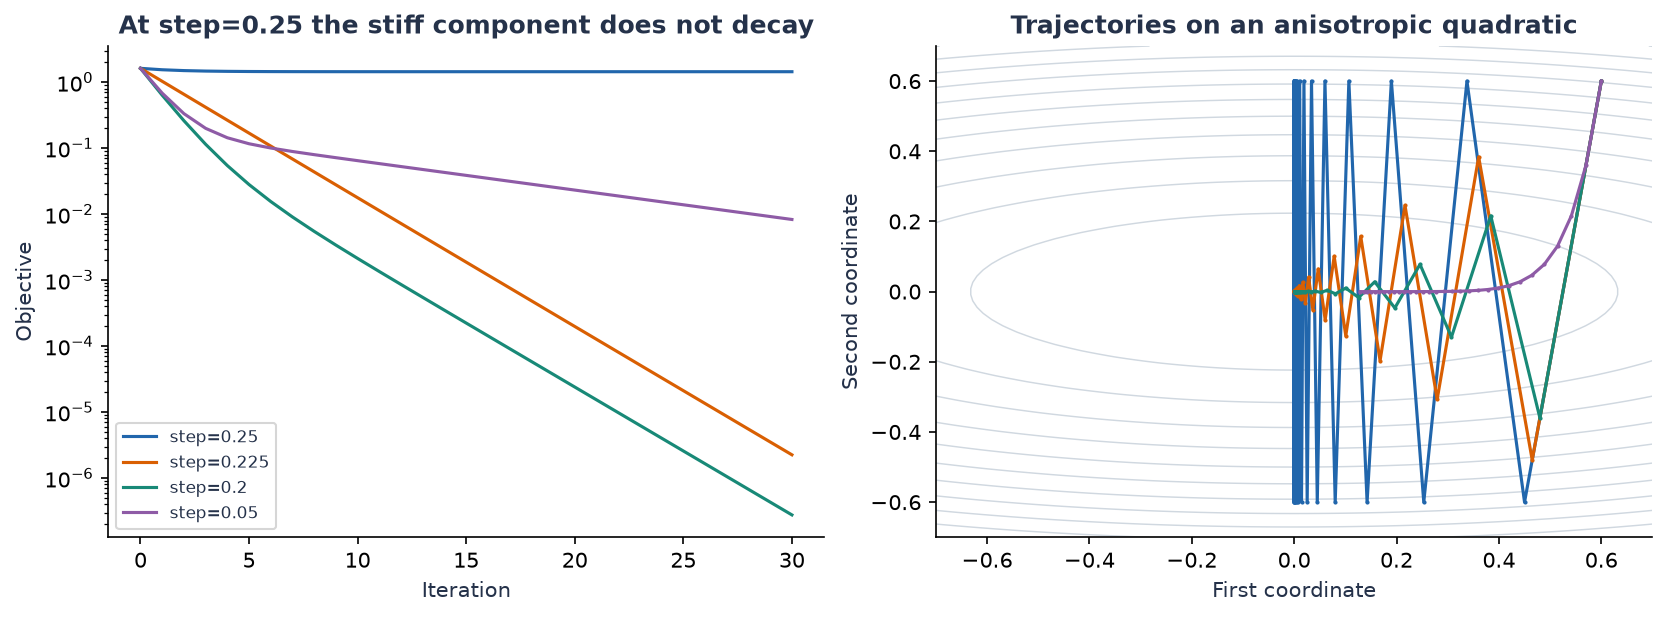

In [2]:
report = run_restoration(inputs, output)
figure("step_size_convergence")

## 2. Define the prior and its adjoint

Let $D$ contain forward vertical and horizontal differences, with a zero last difference along each axis. The smoothness penalty is

$$R(x)=\tfrac12\|Dx\|_F^2,\qquad \nabla R(x)=D^*Dx.$$

The implementation must satisfy $\langle Dx,v\rangle=\langle x,D^*v\rangle$, including boundaries. For this 2D stencil, $\|D\|^2\leq8$. The tests also compare finite-difference directional derivatives with the analytic objective gradient.

In [3]:
from signal_inverse.optimization import gradient, gradient_adjoint
rng = np.random.default_rng(1234)
x = rng.normal(size=(9, 11))
v = rng.normal(size=(9, 11, 2))
lhs, rhs = np.sum(gradient(x) * v), np.sum(x * gradient_adjoint(v))
assert np.isclose(lhs, rhs, atol=1e-12)
print(f"Adjoint identity absolute error: {abs(lhs-rhs):.3e}")

Adjoint identity absolute error: 3.553e-15


## 3. Denoising: fidelity versus smoothness

For $y=x_\star+\varepsilon$, minimize

$$F(x)=\tfrac12\|x-y\|_F^2+\tfrac\lambda2\|Dx\|_F^2,$$
$$\nabla F(x)=x-y+\lambda D^*Dx.$$

We retain the original baseline $\lambda=8$, 100 iterations and $\tau=1.9/(1+8\lambda)$. Images are expressed on $[0,1]$ rather than $[0,255]$; the quadratic objective scales consistently. Gaussian noise is generated from a nominal expected input SNR of 20 dB, with seed zero. A finite realization need not have exactly 20 dB SNR.

A decreasing objective certifies progress toward this model's optimum, not recovery of all true image details. Strong quadratic smoothing can remove edges and texture together with noise.

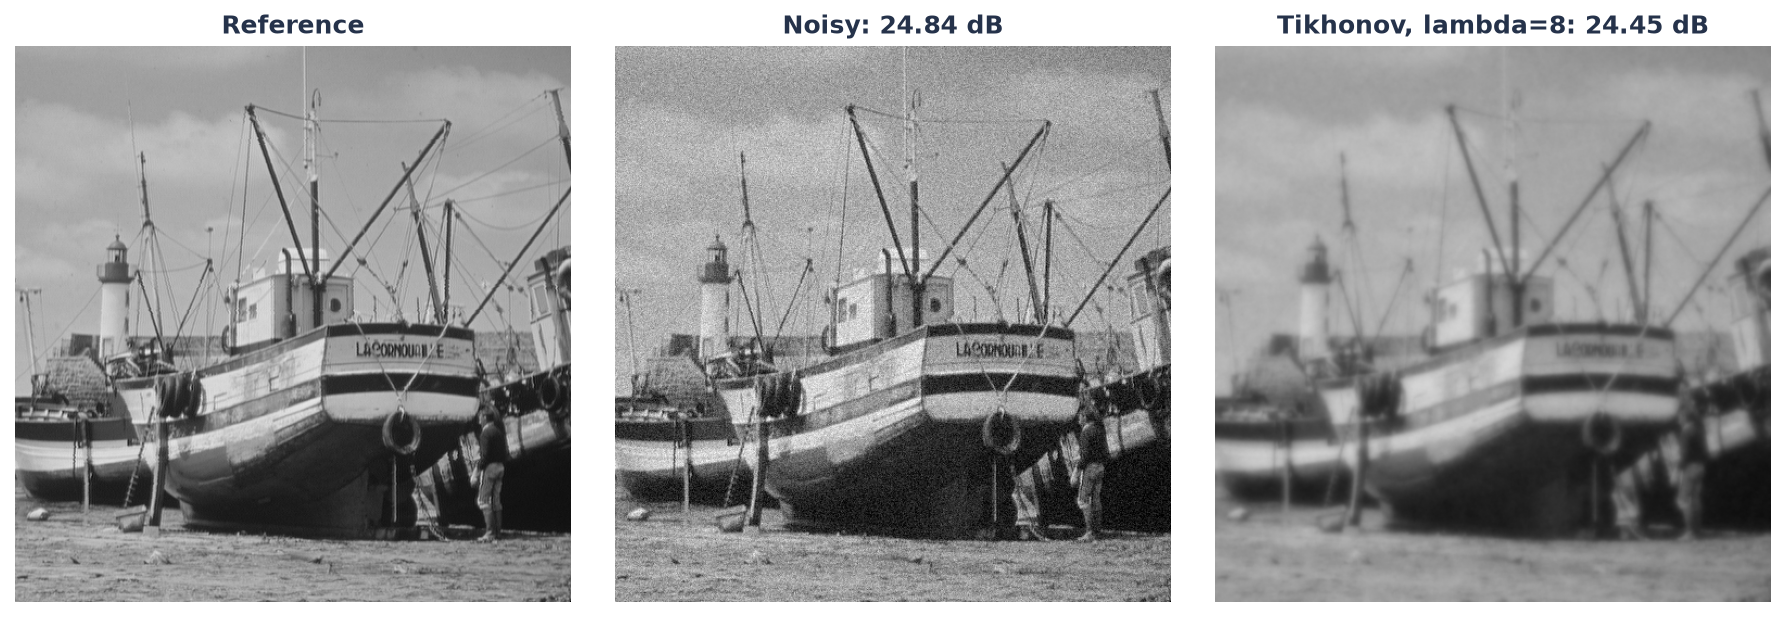

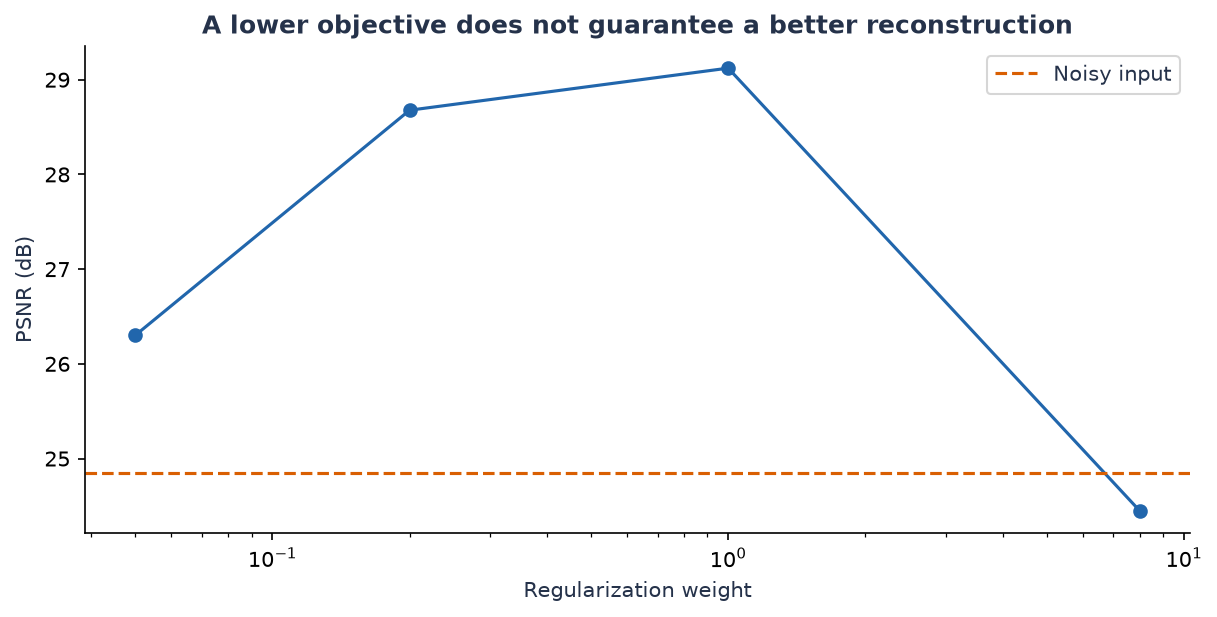

| regularization | iterations | psnr_db | mse |
| --- | --- | --- | --- |
| 0.050 | 100 | 26.300 | 0.002 |
| 0.200 | 100 | 28.678 | 0.001 |
| 1 | 100 | 29.122 | 0.001 |
| 8 | 100 | 24.447 | 0.004 |

In [4]:
figure("tikhonov_denoising")
figure("regularization_tradeoff")
table(report["regularization_sweep"], ["regularization", "iterations", "psnr_db", "mse"])

## 4. Inpainting: preserve what is observed

Let $M$ be a binary mask of observed pixels. Reconstruct by solving

$$\min_x\ \tfrac12\|Dx\|_F^2\quad\text{subject to}\quad M\odot x=y.$$

The projection sets observed locations back to their known values:

$$P_C(u)=M\odot y+(1-M)\odot u.$$

Each iteration takes a gradient step and then projects. We retain 300 iterations and $\tau=1.9/8$, with a deterministic mask observing each pixel with probability 0.1. The realized fraction is measured rather than asserted to be exactly 10%.

This is missing-data reconstruction, not denoising: the observed pixels are noiseless in this experiment. Report both full-image PSNR and PSNR restricted to missing pixels.

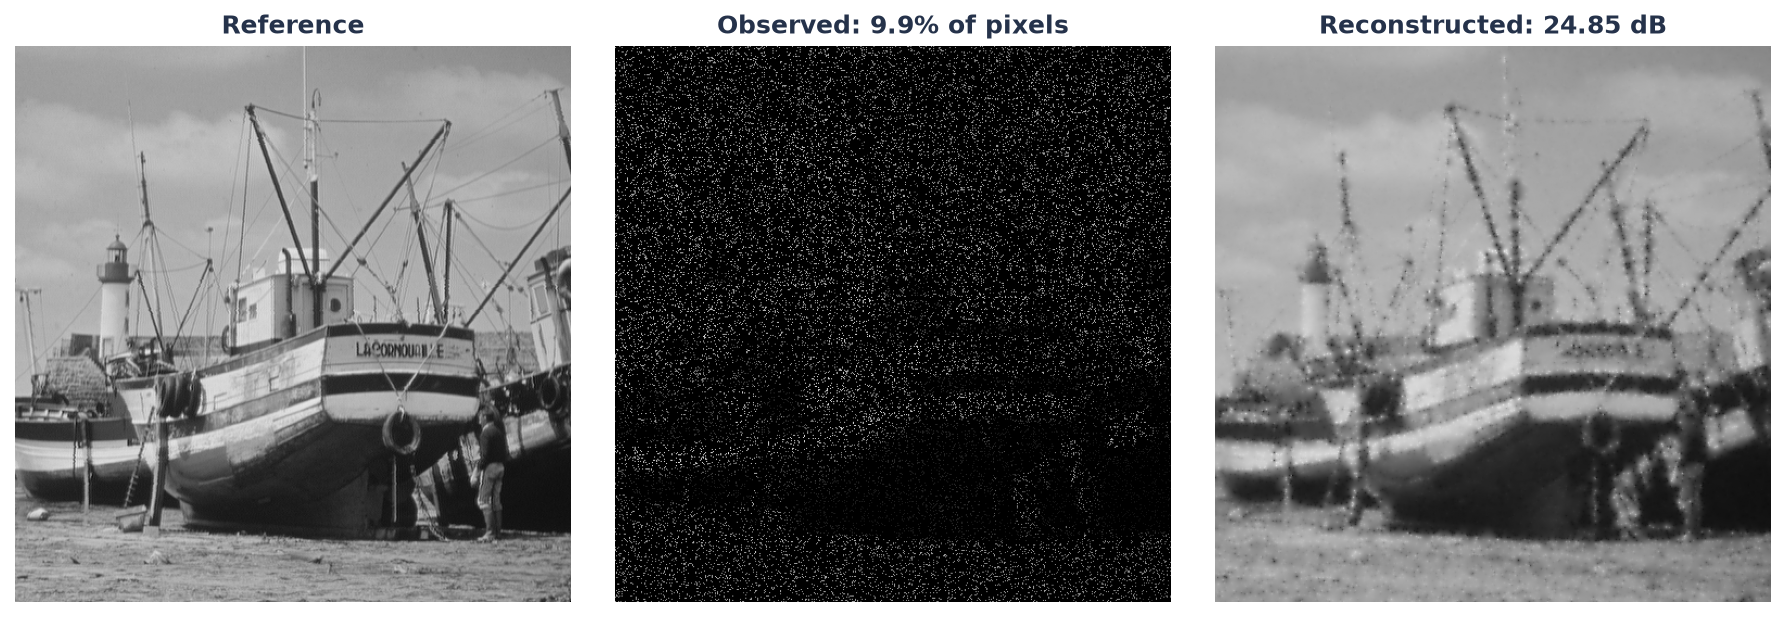

Observed fraction: 9.9319%
Full-image PSNR: 24.85 dB
Missing-pixel PSNR: 24.40 dB
Maximum observed-pixel error: 0.000e+00


In [5]:
figure("inpainting")
print(f"Observed fraction: {report['observed_fraction']:.4%}")
print(f"Full-image PSNR: {report['inpainting_psnr_db']:.2f} dB")
print(f"Missing-pixel PSNR: {report['inpainting_missing_psnr_db']:.2f} dB")
print(f"Maximum observed-pixel error: {report['observed_pixel_max_error']:.3e}")
assert report["observed_pixel_max_error"] == 0

## 5. Convergence and verification

Both objectives are tracked from iteration zero through the final iterate. For small problems, independent dense linear-system solutions verify the denoising optimum and the constrained inpainting optimum. The tests also check that observations stay fixed.

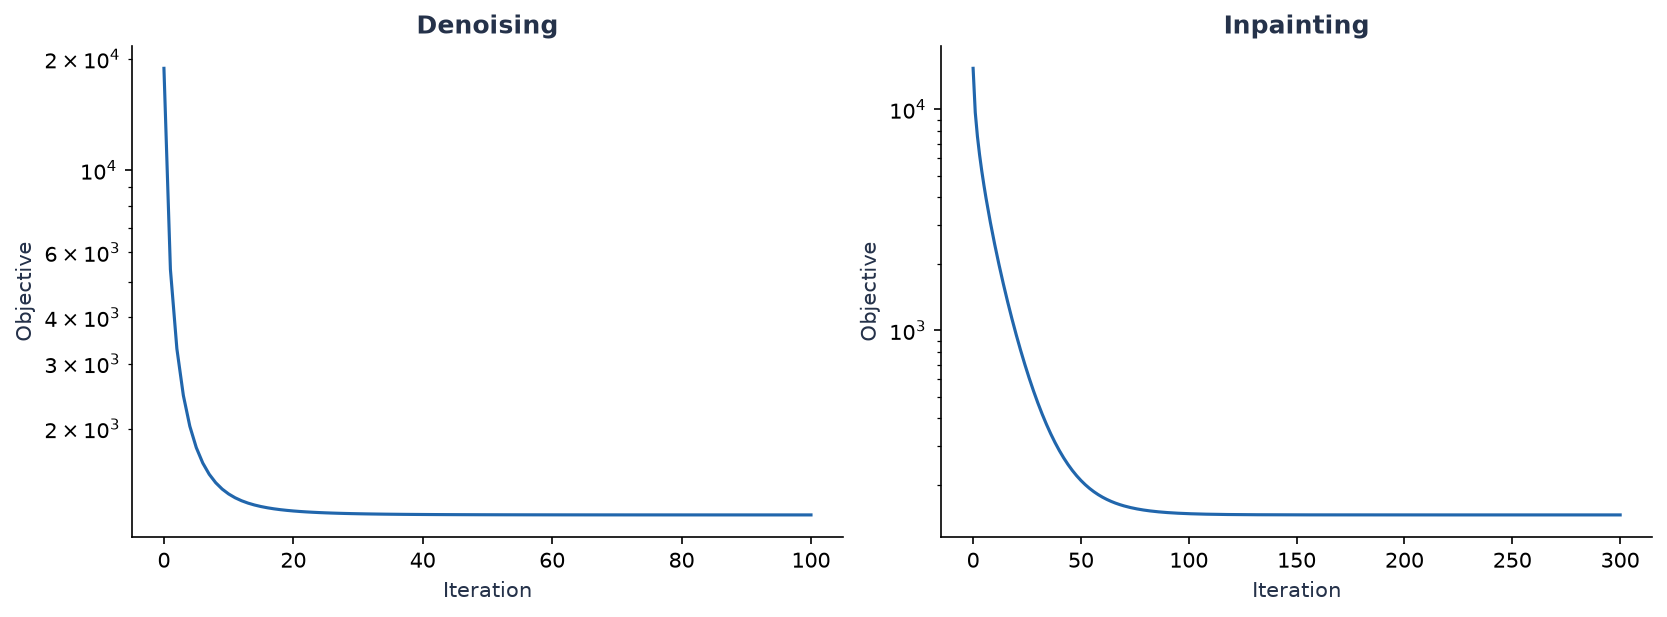

Both measured objective histories are nonincreasing.


In [6]:
figure("restoration_convergence")
assert report["denoising_objective_monotone"]
assert report["inpainting_objective_monotone"]
print("Both measured objective histories are nonincreasing.")

## Findings and limits

The smoothness prior makes incomplete reconstruction possible, but it cannot identify details that the observations and model do not determine. Oversmoothing at $\lambda=8$ is retained and reported, even if it produces worse PSNR than the noisy input. The added regularization sweep illustrates this tradeoff without changing the original baseline.

Across all four studies, the recurring design choice is the same: specify the observation, choose a representation or prior, reconstruct, and check the result against assumptions. A visually plausible output is not sufficient evidence by itself.

**Connections:** compare this quadratic prior with [wavelet thresholding](02_wavelet_image_denoising.ipynb), and the equality constraint with [source reconstruction under a mixing model](03_sparse_source_separation.ipynb).

See the [results](../docs/results.md), [verification guide](../docs/reproducibility.md) and [project bibliography](../REFERENCES.md).